# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
NAME(s) = ""

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$-\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [31]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

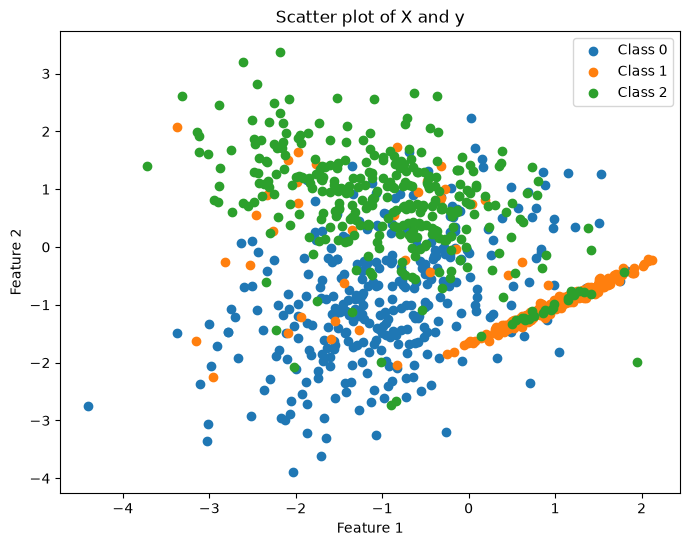

In [32]:
# make a scatter plot of X and y
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
for class_value in range(3):
    plt.scatter(
        X[y == class_value, 0], 
        X[y == class_value, 1], 
        label=f"Class {class_value}"
    )
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Scatter plot of X and y")
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import pandas as pd
import torch
from torch import relu
import torch.nn.functional as F
from sklearn.metrics import accuracy_score


X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, random_state=1234, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_holdout = scaler.transform(X_holdout)

# one-hot encode the labels

# (OneHotEncoder needs 2D input, so I need to reshape to a column)
encoder = OneHotEncoder(sparse_output=False)
y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1))
y_holdout_oh = encoder.transform(y_holdout.reshape(-1, 1))

# making them tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_holdout = torch.tensor(X_holdout, dtype=torch.float32)
y_train_oh = torch.tensor(y_train_oh, dtype=torch.float32)
y_holdout_oh = torch.tensor(y_holdout_oh, dtype=torch.float32)


class MultiClassMLP(object):

    def __init__(self, input_dim, hidden_dim, output_dim, n_hidden_layers=2, learning_rate=0.01, activation="relu"):
            
        # first hidden layer (always)
        self.W_1 = (0.1 * torch.randn(input_dim, hidden_dim)).requires_grad_()
                # multiply by 0.1 to scale the initial weights
        self.b_1 = torch.randn(hidden_dim, requires_grad=True)

        # second hidden layer (only used when n_hidden_layers == 2)
        if n_hidden_layers == 2:
            self.W_2 = (0.1 * torch.randn(hidden_dim, hidden_dim)).requires_grad_()
            self.b_2 = torch.randn(hidden_dim, requires_grad=True)

        # output layer (always)
        self.W_3 = (0.1 * torch.randn(hidden_dim, output_dim)).requires_grad_()
        self.b_3 = torch.randn(output_dim, requires_grad=True)

        self.n_hidden_layers = n_hidden_layers
        self.learning_rate = learning_rate
        self.activation = activation

    def forward(self, X):

        h_1 = torch.matmul(X, self.W_1) + self.b_1

        if self.activation == "relu":
            h_1 = relu(h_1)
        elif self.activation == "tanh":
            h_1 = torch.tanh(h_1)
        else:
            raise ValueError("activation must be 'relu' or 'tanh'")

        h = h_1  # output of the last hidden layer

        if self.n_hidden_layers == 2:
            h_2 = torch.matmul(h_1, self.W_2) + self.b_2

            if self.activation == "relu":
                h_2 = relu(h_2)
            elif self.activation == "tanh":
                h_2 = torch.tanh(h_2)

            h = h_2

        logits = torch.matmul(h, self.W_3) + self.b_3 # logits are the raw scores before softmax

        # softmax means each row becomes probabilities between 0 and 1 that sum to 1
        out = F.softmax(logits, dim=1) # dim = 1 reads across columns, i.e., each row sums to 1

        return out

    def cost(self, out, y):
        # categorical cross-entropy by hand: out = softmax probabilities, y = one-hot labels
        # clamp avoids log(0)
        return -torch.mean(torch.sum(y * torch.log(out.clamp(min=1e-15)), dim=1)) # categoricalcross-entropy loss

    def fit(self, X, y, n_epochs=150):

        for epoch in range(n_epochs):

            randperm = torch.randperm(X.shape[0]) # randperm generates a random permutation of indices for stochastic gradient descent

            for ii in randperm:
                x_batch = X[ii].unsqueeze(0)
                y_batch = y[ii].unsqueeze(0)   # y is one-hot, shape (1, 3)

                out = self.forward(x_batch)

                cost = self.cost(out, y_batch)

                cost.backward()

                with torch.no_grad():
                    self.W_1 -= self.learning_rate * self.W_1.grad
                    self.b_1 -= self.learning_rate * self.b_1.grad

                    if self.n_hidden_layers == 2:
                        self.W_2 -= self.learning_rate * self.W_2.grad
                        self.b_2 -= self.learning_rate * self.b_2.grad

                    self.W_3 -= self.learning_rate * self.W_3.grad
                    self.b_3 -= self.learning_rate * self.b_3.grad

                    # zero gradients
                    self.W_1.grad.zero_()
                    self.b_1.grad.zero_()

                    if self.n_hidden_layers == 2:
                        self.W_2.grad.zero_()
                        self.b_2.grad.zero_()

                    self.W_3.grad.zero_()
                    self.b_3.grad.zero_()

            if epoch % 10 == 0:
                print(f"Epoch {epoch}, Cost: {cost.item():.4f}")

        return self

    def predict(self, X):

        with torch.no_grad(): # disable gradient calculation for prediction
            out = self.forward(X)
            predicted = torch.argmax(out, dim=1) # argmax b/c we want the class with the highest probability

        return predicted

In [29]:
results = []

configs = [
    (1, 4, "relu"),
    (1, 8, "relu"),
    (1, 16, "relu"),
    (1, 32, "relu"),
    (2, 4, "relu"),
    (2, 8, "relu"),
    (2, 16, "relu"),
    (2, 32, "relu"),
    (1, 4, "tanh"),
    (1, 8, "tanh"),
    (1, 16, "tanh"),
    (1, 32, "tanh"),
    (2, 4, "tanh"),
    (2, 8, "tanh"),
    (2, 16, "tanh"),
    (2, 32, "tanh"),
]

for n_hidden_layers, hidden_dim, activation in configs:
    torch.manual_seed(42)

    model = MultiClassMLP(
        input_dim=X_train.shape[1],
        hidden_dim=hidden_dim,
        output_dim=3,
        n_hidden_layers=n_hidden_layers,
        learning_rate=0.01,
        activation=activation
    )

    model.fit(X_train, y_train_oh, n_epochs=200)

    with torch.no_grad():
        train_cost = model.cost(
            model.forward(X_train), y_train_oh
        ).item()

        holdout_cost = model.cost(
            model.forward(X_holdout), y_holdout_oh
        ).item()

    results.append({
        "Hidden layers": n_hidden_layers,
        "Neurons per layer": hidden_dim,
        "Activation": activation,
        "Train Accuracy": round(
            accuracy_score(y_train, model.predict(X_train)), 4
        ),
        "Holdout Accuracy": round(
            accuracy_score(y_holdout, model.predict(X_holdout)), 4
        ),
        "Train cost": train_cost,
        "Holdout cost": holdout_cost
    })

Epoch 0, Cost: 0.5441
Epoch 10, Cost: 0.1113
Epoch 20, Cost: 0.2320
Epoch 30, Cost: 0.1300
Epoch 40, Cost: 0.1723
Epoch 50, Cost: 2.3785
Epoch 60, Cost: 0.0944
Epoch 70, Cost: 0.1837
Epoch 80, Cost: 0.2260
Epoch 90, Cost: 2.0551
Epoch 100, Cost: 0.8748
Epoch 110, Cost: 0.3875
Epoch 120, Cost: 0.2192
Epoch 130, Cost: 1.5664
Epoch 140, Cost: 0.0556
Epoch 150, Cost: 0.4724
Epoch 160, Cost: 0.2676
Epoch 170, Cost: 0.0914
Epoch 180, Cost: 0.1035
Epoch 190, Cost: 1.9446
Epoch 0, Cost: 0.3784
Epoch 10, Cost: 0.1457
Epoch 20, Cost: 0.1166
Epoch 30, Cost: 0.1760
Epoch 40, Cost: 0.0930
Epoch 50, Cost: 0.2454
Epoch 60, Cost: 0.2837
Epoch 70, Cost: 0.1097
Epoch 80, Cost: 0.3256
Epoch 90, Cost: 0.3000
Epoch 100, Cost: 0.1093
Epoch 110, Cost: 0.1538
Epoch 120, Cost: 0.4100
Epoch 130, Cost: 1.1168
Epoch 140, Cost: 0.2327
Epoch 150, Cost: 1.0328
Epoch 160, Cost: 0.1419
Epoch 170, Cost: 0.0864
Epoch 180, Cost: 2.3807
Epoch 190, Cost: 3.1625
Epoch 0, Cost: 0.9346
Epoch 10, Cost: 0.5134
Epoch 20, Cost: 0

In [33]:
results_df = pd.DataFrame(results).round(4)
print(results_df.to_string(index=False))

 Hidden layers  Neurons per layer Activation  Train Accuracy  Holdout Accuracy  Train cost  Holdout cost
             1                  4       relu          0.8113             0.800      0.5755        0.6088
             1                  8       relu          0.8175             0.815      0.5644        0.6058
             1                 16       relu          0.8013             0.800      0.5778        0.6160
             1                 32       relu          0.8225             0.815      0.5374        0.5950
             2                  4       relu          0.8075             0.795      0.5536        0.5992
             2                  8       relu          0.8275             0.800      0.5530        0.6572
             2                 16       relu          0.8275             0.805      0.5290        0.6229
             2                 32       relu          0.8275             0.805      0.5352        0.6093
             1                  4       tanh          0

### Results and Discussion
Everything you wrote is kept word for word. The additions are accuracy sentences in each paragraph and a new tanh vs. ReLU explanation.

Increasing the number of hidden units lowered training cost but did not reliably improve performance on the holdout set. For one-layer ReLU, train cost fell steadily from 0.583 to 0.565 to 0.535 as width went from 8 to 16 to 32, but holdout cost went 0.607, 0.622, 0.586, so there was no consistent trend. With two layers, train cost kept falling with width (e.g. ReLU 0.542 to 0.521), while holdout cost stayed flat or rose (ReLU 0.590 to 0.610), so the gap between the training cost and holdout cost grew. This increased difference between training and holdout cost suggests that wider networks start fitting noise, which makes sense considering the dataset has only two features and 200 samples. Accuracy showed the same pattern. For one-layer ReLU, train accuracy rose from 0.804 to 0.815 to 0.828 with width, while holdout accuracy stayed at 0.805, 0.795, 0.805. Train accuracy also plateaued around 0.83 (0.8275 appears in four configurations). Holdout accuracy stayed between 0.795 and 0.815 for all twelve models, and with only 200 holdout samples that spread is just a few observations, so 8 neurons appears to be enough for this data.

Moving from one hidden layer to two lowered training cost in five of the six matched comparisons. However, the benefit on the holdout set was limited. For ReLU with 8 and 16 neurons, two layers improved holdout cost (0.607 to 0.590 and 0.622 to 0.594), possibly because a narrow single ReLU layer has little capacity to begin with. In the other four comparisons (ReLU with 32 neurons and all three tanh widths), the two-layer model had a slightly worse holdout cost, and the train-to-holdout gap was larger with two layers in five of the six pairs. Accuracy oncemore had similar pattern in which two layers gave equal or higher train accuracy in five of the six pairs, but holdout accuracy moved by 0.02 or less in either direction (four samples or fewer), up for ReLU with 32 neurons (0.805 to 0.815) and down for tanh with 8 neurons (0.815 to 0.795). The conclusion can be made that depth bought a better fit to the training data without clearly improving generalization, again benefitting a simpler moder.

Tanh reached a lower training cost than ReLU in most comparisons (an average of about 0.530 vs. 0.547), with the biggest difference in the smallest network (0.530 vs. 0.583 for one layer and 8 neurons). On the holdout set the two were nearly tied (about 0.598 for tanh vs. 0.602 for ReLU), with no consistent winner. Accuracy had an identical pattern, with mean train accuracy at 0.821 for ReLU and 0.818 for tanh, and mean holdout accuracy at about 0.804 vs. 0.805, implying tanh’s lower cost meant it assigned a higher probability to the correct class on average without getting more samples right. Tanh was ahead on accuracy only in the smallest network (0.814 vs. 0.804 train, 0.815 vs. 0.805 holdout). One plausible explanation is that ReLU outputs zero for any negative input, so a ReLU neuron that starts out negative for most inputs gets little or no gradient and stops learning, which effectively makes a small network less efficient. Tanh always passes some gradient, so every neuron keeps learning. This would also explain why tanh’s advantage is largest with 8 neurons and mostly disappears at 32, where ReLU has enough working neurons. 

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

YOUR TEXT HERE

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our group divided the lab into separate parts so that each member could focus on one section, which improved the quality of everyone’s individual work because we were able to explore our parts in greater depth. The main inefficiency we encountered was communication and scheduling, as we did not meet as a group until the Monday before the lab was due. This left us with limited time to compare results, resolve inconsistencies between sections, and complete the write-up together, however, we do not believe this hindered results. In the next lab, we will schedule a group meeting within the first few days of the lab being released, ideally during the same week, and we will set a shared calendar reminder and a mid-week check-in in our group chat so that everyone’s progress is visible well before the deadline.